# RSSI-gated fallback: which threshold, and should it be dynamic?

**The problem.** In the cooperative scheme (R6) the leader checks the helper's handed slot. If it decodes no SCI
from the helper there, it takes the next handed slot back (fallback). When the helper did transmit but its SCI
failed at the leader, both then send the TB in the same slot on the same subchannels: a *double transmission*.

**The candidate fix.** Fall back only if no helper SCI was decoded **and** the SL-RSSI on the handed subchannels
is below a threshold. A threshold can be **fixed** (dBm per RB) or **dynamic**: relative to the helper's
PSSCH-RSRP, which the leader measures whenever it does decode the helper, or chosen per context (route, traffic).

**What decides it.** A threshold avoids double transmissions but also suppresses some true fallbacks, when other
vehicles happen to transmit on the handed subchannels. So we need the value of each:
- what a double transmission costs the members, compared with the helper's copy sent alone;
- what a true fallback recovers.

**Data.** `out/rssi_v3`: R6, 60 background vehicles, seed 1, three routes x two traffic types (laptop,
logging-only build `40a5601`; the protocol is unchanged). One row per fallback check
(`<cell>_fbchk.csv`), joined with the per-transmission logs (`_ltx`, `_htx`) and the per-member reception log
(`_att`). The split of the received power by transmitter is simulation ground truth. A UE measures only the total.

| term | meaning |
|---|---|
| check | the leader listens in the helper's handed slot h after a not-all-ACK decision |
| A | helper transmitted in h, the leader decoded its SCI: no fallback |
| B | helper transmitted in h, SCI not decoded: false fallback (double transmission if the helper relays again) |
| C | helper silent in h: true fallback |
| s3 | the TB's next copy after h, the slot the fallback takes; who sent it: L, H, or LH (double) |
| member in need | a member that had not decoded the TB up to h |
| recovered | a member in need that decodes the TB at s3 |
| RSSI | per RB on the handed subchannels: helper + others + noise (noise -113.4 dBm per RB) |

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, os
import rssi_threshold as R
FIG = 'figures/rssi_fallback'; os.makedirs(FIG, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9, 'axes.grid': True, 'grid.alpha': 0.3})
COL = {'A': '#4C78A8', 'B': '#E45756', 'C': '#54A24B'}
LBL = {'A': 'A: helper sent, SCI decoded', 'B': 'B: helper sent, SCI missed', 'C': 'C: helper silent'}
d = R.load('out/rssi_v3')
d['helper_ref'] = R.helper_reference(d)
ra = R.r_alone_by_cell(d)
print(len(d), 'checks;', d.drop_duplicates('cell').tbs.sum(), 'TBs in the KPI windows')
d.pivot_table(index=['route', 'traffic'], columns='cls', values='t', aggfunc='size', fill_value=0)

2170 checks; 2616 TBs in the KPI windows


cls                       A   B    C
route        traffic                
Highway      aperiodic  265  34  106
             periodic   374   2   15
Roundabout E aperiodic  298  34   56
             periodic   347   2   14
Roundabout W aperiodic  245  18   63
             periodic   285   2   10

## 1. What the leader measures

The B checks are the problem, and they almost all come from aperiodic traffic. In every B check the helper's PSCCH
reached the leader and failed under interference. The RSSI is high because the helper's own power is in it. The C
checks are often not quiet: another vehicle transmits on the handed subchannels in about three quarters of them, so
their RSSI has a long upper tail that overlaps B.

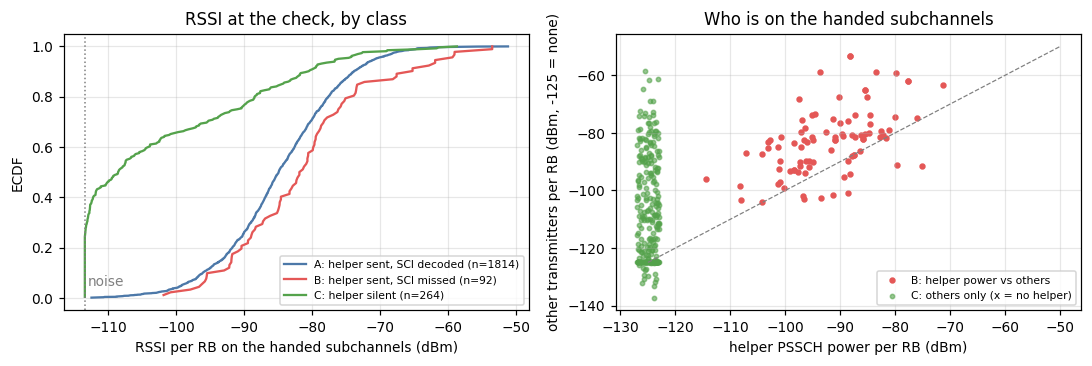

,p5,p25,p50,p75,p95,others_present
A,-99.2,-90.2,-84.9,-78.9,-70.7,0.63
B,-96.0,-88.8,-81.6,-76.0,-60.7,1.00
C,-113.4,-113.4,-108.5,-90.8,-76.2,0.76


In [2]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for k in 'ABC':
    x = np.sort(d[d.cls == k].rssi.values)
    ax[0].plot(x, np.arange(1, len(x) + 1) / len(x), color=COL[k], label=f'{LBL[k]} (n={len(x)})')
ax[0].axvline(R.NOISE_DBM_PER_RB, color='grey', ls=':', lw=1); ax[0].text(R.NOISE_DBM_PER_RB + 0.5, 0.05, 'noise', color='grey')
ax[0].set_xlabel('RSSI per RB on the handed subchannels (dBm)'); ax[0].set_ylabel('ECDF'); ax[0].legend(fontsize=7, loc='lower right')
ax[0].set_title('RSSI at the check, by class')
bc = d[d.cls.isin(['B', 'C'])]
ax[1].scatter(bc[bc.cls == 'B'].p_helper_rb, bc[bc.cls == 'B'].p_other_rb.fillna(-125), s=10, color=COL['B'], label='B: helper power vs others')
ax[1].scatter(np.full((bc.cls == 'C').sum(), -125.0) + np.random.default_rng(0).uniform(-2, 2, (bc.cls == 'C').sum()),
              bc[bc.cls == 'C'].p_other_rb.fillna(-125), s=8, color=COL['C'], alpha=0.6, label='C: others only (x = no helper)')
ax[1].plot([-125, -50], [-125, -50], color='grey', lw=0.8, ls='--')
ax[1].set_xlabel('helper PSSCH power per RB (dBm)'); ax[1].set_ylabel('other transmitters per RB (dBm, -125 = none)')
ax[1].set_title('Who is on the handed subchannels'); ax[1].legend(fontsize=7)
fig.tight_layout(); fig.savefig(f'{FIG}/rssi_by_class.pdf'); plt.show()
q = [5, 25, 50, 75, 95]
pd.DataFrame({k: np.percentile(d[d.cls == k].rssi, q) for k in 'ABC'}, index=[f'p{x}' for x in q]).round(1).T.assign(
    others_present=[(d[d.cls == k].p_other > -998).mean().round(2) for k in 'ABC'])

## 2. What the slot after the check delivers

This is the key input. The table gives, for the members in need, the share that decode the TB at s3:
- with a double transmission (B, s3 = LH);
- with the helper's copy alone (A, s3 = H): the counterfactual for B if the leader withholds;
- with the leader's fallback alone (C, s3 = L): what is lost when a true fallback is suppressed.

The two copies of a double carry the same TB on the same subchannels. Each is interference to the other, but a
member can still decode either one, and both enter the same HARQ buffer. A double therefore costs much less than a
plain collision. A suppressed true fallback, by contrast, leaves the last slot empty.

In [3]:
def rate(sel):
    g = sel.groupby('cell')[['n_rec3', 'n_need']].sum()
    return g.n_rec3 / g.n_need, g.n_need
dbl, nb = rate(d[(d.cls == 'B') & (d.s3_who == 'LH')])
fb, nc = rate(d[(d.cls == 'C') & (d.s3_who == 'L')])
t = pd.DataFrame({'double (B, LH)': dbl, 'members in need (B)': nb, 'helper alone (A, H)': pd.Series(ra),
                  'fallback alone (C, L)': fb, 'members in need (C)': nc})
t.index = [i.replace('_ivd30', '').replace('_moderate_s1', '') for i in t.index]
tot = lambda m: (lambda g: g.n_rec3.sum() / g.n_need.sum())(d[m])
print(f"pooled: double {tot((d.cls=='B')&(d.s3_who=='LH')):.3f}, helper alone "
      f"{tot((d.cls=='A')&(d.s3_who=='H')&(d.n_need>0)):.3f}, fallback alone {tot((d.cls=='C')&(d.s3_who=='L')):.3f}")
print('checks by class and sender at s3:'); print(d.groupby(['cls', 's3_who']).size().unstack(fill_value=0))
t.round(3)

pooled: double 0.346, helper alone 0.298, fallback alone 0.357
checks by class and sender at s3:
s3_who    -    H    L  LH
cls                      
A       910  904    0   0
B        12    0    6  74
C        45    0  219   0


,"double (B, LH)",members in need (B),"helper alone (A, H)","fallback alone (C, L)",members in need (C)
hwy_aperiodic1tb,0.385,52,0.665,0.381,546
hwy_periodic1tb,0.000,1,0.667,0.602,88
rbtE_aperiodic1tb,0.361,36,0.221,0.334,329
rbtE_periodic1tb,1.000,2,0.326,0.430,79
rbt_aperiodic1tb,0.194,36,0.164,0.297,337
rbt_periodic1tb,1.000,3,0.222,0.159,63


## 3. A fixed threshold

For a threshold x, the rule withholds the fallback when RSSI ≥ x. The effect is counted per (TB, member) pair:
- **gained:** in a suppressed double, the helper's copy goes alone. Its recoveries are estimated with the helper-alone
  rate of the same cell, minus what the double delivered.
- **lost:** in a suppressed true fallback, or a B check where the helper had already stopped, the slot stays empty and
  its recoveries are lost.
- **net** in percentage points of group PRR: (gained − lost) / (TBs × 8 members), over the six runs.
- **saved:** fallback transmissions withheld, which also means less interference for other vehicles.

The helper-alone counterfactual comes from A checks, which saw less interference than B checks. If anything it
overstates the gain of avoiding a double.

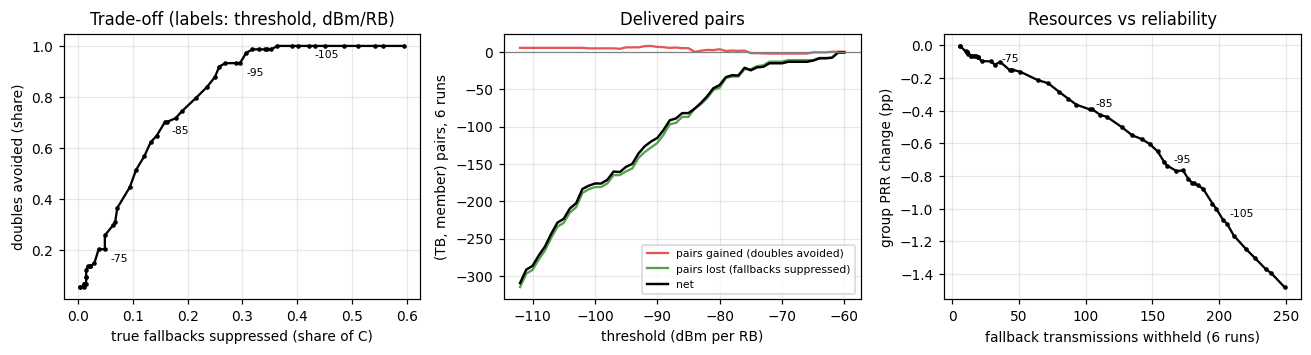

,doubles_avoided,doubles,true_fb_lost,true_fb,pairs_gained,pairs_lost,net_pp,tx_saved
x,,,,,,,,
-110.0,74,74,143,264,5.424,292.0,-1.369,235
-105.0,74,74,111,264,5.424,229.0,-1.068,203
-100.0,73,74,91,264,4.759,181.0,-0.842,181
-95.0,69,74,78,264,6.101,160.0,-0.735,161
-90.0,62,74,62,264,6.672,122.0,-0.551,135
-85.0,52,74,42,264,5.009,87.0,-0.392,103
-80.0,33,74,25,264,3.577,48.0,-0.212,64
-75.0,15,74,13,264,-1.694,23.0,-0.118,32
-70.0,10,74,6,264,-2.229,13.0,-0.073,19


In [4]:
grid = np.arange(-112, -59, 1.0)
F = pd.DataFrame([R.evaluate(d, R.rule_suppress(d, 'fixed', x), ra) | {'x': x} for x in grid])
fig, ax = plt.subplots(1, 3, figsize=(12, 3.3))
ax[0].plot(F.true_fb_lost / F.true_fb, F.doubles_avoided / F.doubles, '-o', ms=2, color='k')
for x in (-105, -95, -85, -75):
    r = F[F.x == x].iloc[0]; ax[0].annotate(f'{x:.0f}', (r.true_fb_lost / r.true_fb, r.doubles_avoided / r.doubles), fontsize=7, xytext=(4, -8), textcoords='offset points')
ax[0].set_xlabel('true fallbacks suppressed (share of C)'); ax[0].set_ylabel('doubles avoided (share)'); ax[0].set_title('Trade-off (labels: threshold, dBm/RB)')
ax[1].plot(F.x, F.pairs_gained, color=COL['B'], label='pairs gained (doubles avoided)')
ax[1].plot(F.x, -F.pairs_lost, color=COL['C'], label='pairs lost (fallbacks suppressed)')
ax[1].plot(F.x, F.net_pairs, color='k', lw=1.6, label='net'); ax[1].axhline(0, color='grey', lw=0.8)
ax[1].set_xlabel('threshold (dBm per RB)'); ax[1].set_ylabel('(TB, member) pairs, 6 runs'); ax[1].legend(fontsize=7); ax[1].set_title('Delivered pairs')
ax[2].plot(F.tx_saved, F.net_pp, '-o', ms=2, color='k')
for x in (-105, -95, -85, -75):
    r = F[F.x == x].iloc[0]; ax[2].annotate(f'{x:.0f}', (r.tx_saved, r.net_pp), fontsize=7, xytext=(4, 2), textcoords='offset points')
ax[2].set_xlabel('fallback transmissions withheld (6 runs)'); ax[2].set_ylabel('group PRR change (pp)'); ax[2].set_title('Resources vs reliability')
fig.tight_layout(); fig.savefig(f'{FIG}/fixed_threshold.pdf'); plt.show()
F[F.x.isin([-110, -105, -100, -95, -90, -85, -80, -75, -70])].set_index('x')[
    ['doubles_avoided', 'doubles', 'true_fb_lost', 'true_fb', 'pairs_gained', 'pairs_lost', 'net_pp', 'tx_saved']].round(3)

## 4. Dynamic thresholds

Two ways to adapt the threshold, both causal (they use only what the leader knew before the check):
- **helper-relative:** withhold when RSSI ≥ P̂_helper − δ, where P̂_helper is an EWMA (α = 0.1, in dB) of the
  helper's PSSCH-RSRP over the earlier checks in which the leader decoded that helper. This follows the helper's
  link, which varies a lot on the roundabout. Before the first estimate it falls back to −95 dBm.
- **per context:** the best fixed threshold chosen separately for each route and traffic type. This is an oracle,
  an upper bound on any context-aware rule.

A dynamic rule is worth having only if it moves the trade-off curve: more doubles avoided for the same true
fallbacks lost.

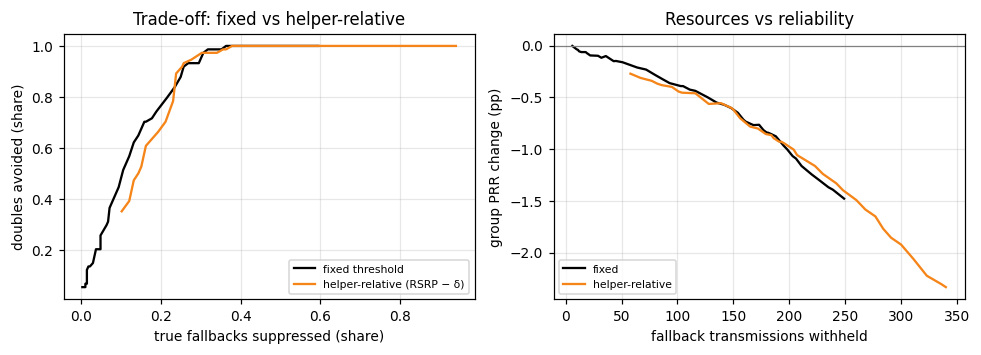

RSSI - helper reference (dB), by class:
     count  mean   std   min   25%   50%   75%   max
cls                                                 
B     90.0   7.1   9.7 -15.0  -0.1   5.6  15.3  34.4
C    262.0 -12.7  14.9 -37.4 -24.4 -17.0  -1.3  27.5


In [5]:
deltas = np.arange(-10, 31, 1.0)
Rl = pd.DataFrame([R.evaluate(d, R.rule_suppress(d, 'relative', x), ra) | {'x': x} for x in deltas])
fig, ax = plt.subplots(1, 2, figsize=(9, 3.3))
ax[0].plot(F.true_fb_lost / F.true_fb, F.doubles_avoided / F.doubles, color='k', label='fixed threshold')
ax[0].plot(Rl.true_fb_lost / Rl.true_fb, Rl.doubles_avoided / Rl.doubles, color='#F58518', label='helper-relative (RSRP − δ)')
ax[0].set_xlabel('true fallbacks suppressed (share)'); ax[0].set_ylabel('doubles avoided (share)'); ax[0].legend(fontsize=7)
ax[0].set_title('Trade-off: fixed vs helper-relative')
ax[1].plot(F.tx_saved, F.net_pp, color='k', label='fixed')
ax[1].plot(Rl.tx_saved, Rl.net_pp, color='#F58518', label='helper-relative')
ax[1].axhline(0, color='grey', lw=0.8); ax[1].set_xlabel('fallback transmissions withheld'); ax[1].set_ylabel('group PRR change (pp)')
ax[1].legend(fontsize=7); ax[1].set_title('Resources vs reliability')
fig.tight_layout(); fig.savefig(f'{FIG}/dynamic_threshold.pdf'); plt.show()
x = d[d.cls.isin(['B', 'C'])]
print('RSSI - helper reference (dB), by class:'); print((x.rssi - x.helper_ref).groupby(x.cls).describe().round(1))

In [6]:
# per-context oracle: the best threshold per route and traffic, "none" = no gate
rows = []
for cell, g in d.groupby('cell'):
    rag = {cell: ra.get(cell, np.nan)}
    best = max([(np.inf, R.evaluate(g, pd.Series(False, index=g.index), rag))] +
               [(x, R.evaluate(g, R.rule_suppress(g, 'fixed', x), rag)) for x in grid], key=lambda p: p[1]['net_pairs'])
    e95 = R.evaluate(g, R.rule_suppress(g, 'fixed', -95), rag)
    rows.append(dict(route=g.route.iloc[0], traffic=g.traffic.iloc[0], B=(g.cls == 'B').sum(), C=(g.cls == 'C').sum(),
                     best_threshold='none' if not np.isfinite(best[0]) else best[0], best_net_pp=best[1]['net_pp'],
                     net_pp_at_minus95=e95['net_pp'], withheld_at_minus95=e95['tx_saved']))
pd.DataFrame(rows).round(3)

,route,traffic,B,C,best_threshold,best_net_pp,net_pp_at_minus95,withheld_at_minus95
0,Highway,aperiodic,34,106,none,0.000,-1.908,61
1,Highway,periodic,2,15,none,0.000,-0.134,4
2,Roundabout E,aperiodic,34,56,-61.0,0.006,-1.028,53
3,Roundabout E,periodic,2,14,none,0.000,-0.124,2
4,Roundabout W,aperiodic,18,63,none,0.000,-0.780,37
5,Roundabout W,periodic,2,10,none,0.000,-0.279,4


## 5. Decision

**No RSSI gate for reliability, fixed or dynamic.** On these runs every threshold lowers the group PRR:
- **Fixed:** −0.21 pp at −80 dBm per RB, −0.74 pp at −95 dBm.
- **Dynamic:** the helper-relative rule traces about the same trade-off curve as a fixed threshold, so adapting the
  threshold to the helper's RSRP does not help. The per-context oracle picks no gate in 5 of 6 cells; in the
  sixth (Roundabout E, aperiodic) its best threshold, −61 dBm, gains 0.006 pp.
- **Why:** each avoided double gains little. The two copies share the TB, and members recover the TB about as often
  as from a single copy: pooled, 35 % of the members in need decode the double, against 30 % for a helper copy
  alone and 36 % for a true fallback. Each suppressed true fallback loses the last
  chance of about a third of its members in need. Interference on the handed subchannels is too common for an energy
  test to tell "helper present" from "someone else present".
- **Where a double does hurt:** on the highway with aperiodic traffic the helper alone recovers more than the double
  (0.67 against 0.39). There are too few doubles for that to outweigh the lost fallbacks.

**If the objective were resources or interference.** A gate saves transmissions: a high threshold such as −80 dBm
per RB withholds 64 fallback copies in six runs for −0.2 pp. That is a separate trade-off and should be stated as
one. It needs no dynamic rule.

**For the paper.** Report the double transmissions as a measured limitation: 26 % of fallbacks with 60 vehicles,
almost all aperiodic. Add that an energy gate does not pay off, because doubles cost little reliability and true
fallbacks are valuable. The better levers are those that make the helper's SCI decodable at the leader, not
detection after the fact.

**Limits of this analysis.**
- One seed per cell on the laptop: 74 doubles and 264 true fallbacks in all.
- The helper-alone counterfactual is estimated from other checks, not simulated.
- Recoveries are counted at s3 only.
- Confirming would need the same logging on more seeds, for example R6 at 60 vehicles with seeds 1-10 on the
  remote. Gating the fallback in the simulator and measuring PRR directly would be a stronger test still.